# Etapa 1 — Exploração dos dados e verificação dos atributos

**Objetivo:** verificar, com evidência numérica e visual, se a escolha de atributos registrada no `README.md` foi sensata.

Atributos **escolhidos** (decisão de 2026-11-10):
`DESCR_TIPOLOCAL`, `DESCR_SUBTIPOLOCAL`, `BAIRRO`, `DESCR_PERIODO` + derivados temporais (`dia_semana`, `mes`, `hora`).

Atributos **descartados**: `DESCR_CONDUTA`, `CIRCUNSTANCIA`, `MARCA_OBJETO`.

Este notebook **não treina modelo** e **não grava arquivos**. Ele só lê `data/raw/CelularesSubtraidos_2025.xlsx` e mede associação entre cada atributo candidato e o alvo (roubo = 1, furto = 0).

> O conjunto de 2026 **não é aberto aqui**: ele está reservado para o teste final.

## 1. Importações

In [1]:
# Importa pandas para manipular tabelas (DataFrames) em memória.
import pandas as pd
# Importa numpy para cálculos numéricos vetorizados (médias, raiz quadrada, etc.).
import numpy as np
# Importa a interface de gráficos do matplotlib, usada em todas as figuras do notebook.
import matplotlib.pyplot as plt
# Importa o teste de chi-quadrado de independência, base do cálculo do V de Cramér.
from scipy.stats import chi2_contingency
# Importa a função que lê o Excel de um ano sem aplicar filtro algum (visão bruta).
from src.data.loader import carregar_ano
# Importa o filtro de município, para medir quantas linhas sobram só da capital.
from src.data.loader import filtar_sao_paulo
# Importa a função que cria a coluna 'target' (0 = furto, 1 = roubo) e descarta outras rubricas.
from src.data.loader import definir_alvo

# Pede ao pandas para não truncar o texto das colunas largas (nomes de bairro, por exemplo).
pd.set_option('display.max_colwidth', 60)
# Amplia a largura da saída do pandas para as tabelas caberem sem quebra de linha.
pd.set_option('display.width', 200)
# Confirma no console que as importações terminaram sem erro.
print('Importações concluídas.')

Importações concluídas.


## 2. Carregamento bruto de 2025 (antes de qualquer filtro)

In [2]:
# Lê o arquivo completo de 2025 sem filtrar município nem rubrica (visão bruta da fonte).
df_bruto = carregar_ano(2025)
# Exibe o número de linhas e de colunas do arquivo bruto.
print(f'Linhas: {df_bruto.shape[0]:,} | Colunas: {df_bruto.shape[1]}')
# Lista todas as colunas disponíveis, para conferir quais atributos existiam para escolher.
print('\nColunas disponíveis na fonte:')
# Percorre as colunas numeradas para facilitar a leitura da lista.
for i, coluna in enumerate(df_bruto.columns, start=1):
    # Imprime o índice e o nome de cada coluna da planilha.
    print(f'  {i:2d}. {coluna}')

Linhas: 383,635 | Colunas: 55

Colunas disponíveis na fonte:
   1. ID_DELEGACIA
   2. NOME_DEPARTAMENTO
   3. NOME_SECCIONAL
   4. NOME_DELEGACIA
   5. NOME_MUNICIPIO
   6. ANO_BO
   7. NUM_BO
   8. VERSAO
   9. NOME_DEPARTAMENTO_CIRC
  10. NOME_SECCIONAL_CIRC
  11. NOME_DELEGACIA_CIRC
  12. NOME_MUNICIPIO_CIRC
  13. DATA_OCORRENCIA_BO
  14. HORA_OCORRENCIA
  15. DESCRICAO_APRESENTACAO
  16. DATAHORA_REGISTRO_BO
  17. DATA_COMUNICACAO_BO
  18. DATAHORA_IMPRESSAO_BO
  19. DESCR_PERIODO
  20. AUTORIA_BO
  21. FLAG_INTOLERANCIA
  22. TIPO_INTOLERANCIA
  23. FLAG_FLAGRANTE
  24. FLAG_STATUS
  25. DESC_LEI
  26. FLAG_ATO_INFRACIONAL
  27. RUBRICA
  28. DESCR_CONDUTA
  29. DESDOBRAMENTO
  30. CIRCUNSTANCIA
  31. DESCR_TIPOLOCAL
  32. DESCR_SUBTIPOLOCAL
  33. CIDADE
  34. BAIRRO
  35. CEP
  36. LOGRADOURO_VERSAO
  37. LOGRADOURO
  38. NUMERO_LOGRADOURO
  39. LATITUDE
  40. LONGITUDE
  41. CONT_OBJETO
  42. DESCR_MODO_OBJETO
  43. DESCR_TIPO_OBJETO
  44. DESCR_SUBTIPO_OBJETO
  45. DESCR_UNIDAD

## 3. Efeito dos filtros (município e rubrica)

Confere quantas linhas cada filtro remove e se o recorte declarado no `README.md` corresponde ao que o código faz.

In [3]:
# Conta as ocorrências por município para mostrar o peso da capital no arquivo estadual.
contagem_municipio = df_bruto['NOME_MUNICIPIO'].value_counts()
# Exibe os 10 municípios com mais registros.
print('Top 10 municípios (linhas brutas):')
# Imprime a série já ordenada por frequência.
print(contagem_municipio.head(10).to_string())

# Lista todas as rubricas presentes, para mostrar o que existe além de roubo e furto.
print('\nRubricas presentes no arquivo bruto:')
# Imprime a contagem por rubrica.
print(df_bruto['RUBRICA'].value_counts().to_string())

# Aplica o filtro de município usado no projeto (apenas 'S.PAULO').
df_sp = filtar_sao_paulo(df_bruto)
# Aplica o filtro de rubrica e cria a coluna 'target' (0 = furto, 1 = roubo).
df = definir_alvo(df_sp)

# Monta o funil de filtragem para deixar explícito quanto cada etapa remove.
print('\nFunil de filtragem:')
# Mostra o total bruto de linhas lidas do Excel.
print(f'  1. Arquivo bruto .................. {df_bruto.shape[0]:>9,} linhas')
# Mostra quantas linhas restam após manter apenas a capital.
print(f'  2. Após filtro S.PAULO ............ {df_sp.shape[0]:>9,} linhas')
# Mostra quantas linhas restam após manter apenas roubo e furto.
print(f'  3. Após filtro roubo/furto ........ {df.shape[0]:>9,} linhas')
# Calcula o percentual final retido em relação ao arquivo bruto.
print(f'  Retenção final: {100 * df.shape[0] / df_bruto.shape[0]:.1f}% das linhas brutas')

Top 10 municípios (linhas brutas):
NOME_MUNICIPIO
S.PAULO                216129
GUARULHOS               10821
CAMPINAS                 9380
S.ANDRE                  7720
S.BERNARDO DO CAMPO      6659
OSASCO                   6612
PRAIA GRANDE             4100
RIBEIRAO PRETO           3996
S.VICENTE                3813
SOROCABA                 3680

Rubricas presentes no arquivo bruto:
RUBRICA
Furto (art. 155)                                                                                                  169628
Roubo (art. 157)                                                                                                  135763
Perda/Extravio                                                                                                     52074
Localização/Apreensão e Entrega de veículo                                                                          6486
Outros não criminal                                                                                                 1993

## 4. Balanceamento das classes

Distribuição do alvo (linhas, antes da consolidação por boletim):
  Furto (0):  106,392 linhas (57.9%)
  Roubo (1):   77,406 linhas (42.1%)
  Razão furto/roubo: 1.37 : 1


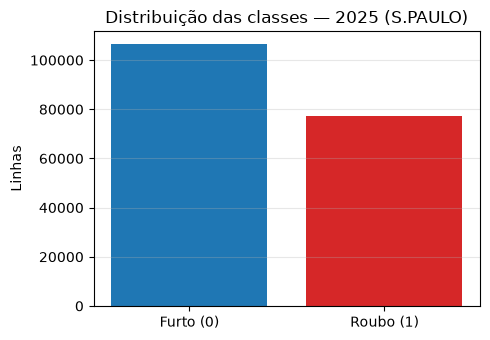

Leitura: desequilíbrio moderado (≈1,4:1). Justifica F1 macro em vez de acurácia simples.


In [4]:
# Conta quantas linhas existem em cada classe do alvo (0 = furto, 1 = roubo).
contagem_alvo = df['target'].value_counts().sort_index()
# Calcula a proporção de cada classe para avaliar o desequilíbrio.
proporcao_alvo = df['target'].value_counts(normalize=True).sort_index()
# Exibe o cabeçalho da seção.
print('Distribuição do alvo (linhas, antes da consolidação por boletim):')
# Mostra a contagem e a proporção da classe furto.
print(f'  Furto (0): {contagem_alvo[0]:>8,} linhas ({100 * proporcao_alvo[0]:.1f}%)')
# Mostra a contagem e a proporção da classe roubo.
print(f'  Roubo (1): {contagem_alvo[1]:>8,} linhas ({100 * proporcao_alvo[1]:.1f}%)')
# Calcula a razão entre a classe majoritária e a minoritária.
print(f'  Razão furto/roubo: {contagem_alvo[0] / contagem_alvo[1]:.2f} : 1')

# Cria a figura e o eixo do gráfico de barras das classes.
fig, ax = plt.subplots(figsize=(5, 3.5))
# Desenha uma barra para cada classe, com cores distintas.
ax.bar(['Furto (0)', 'Roubo (1)'], contagem_alvo.values, color=['tab:blue', 'tab:red'])
# Define o rótulo do eixo vertical.
ax.set_ylabel('Linhas')
# Define o título do gráfico.
ax.set_title('Distribuição das classes — 2025 (S.PAULO)')
# Adiciona grade horizontal leve para facilitar a leitura dos valores.
ax.grid(axis='y', alpha=0.3)
# Ajusta as margens da figura.
fig.tight_layout()
# Exibe a figura no notebook.
plt.show()

# Registra a leitura do gráfico: o desequilíbrio é moderado, o que justifica usar F1 macro.
print('Leitura: desequilíbrio moderado (≈1,4:1). Justifica F1 macro em vez de acurácia simples.')

## 5. Ausências e cardinalidade dos atributos candidatos

Cardinalidade alta encarece o one-hot; percentual alto de ausência enfraquece o atributo.

In [5]:
# Lista os atributos escolhidos para o modelo, conforme a decisão registrada no README.
escolhidos = ['DESCR_TIPOLOCAL', 'DESCR_SUBTIPOLOCAL', 'BAIRRO', 'DESCR_PERIODO']
# Lista os atributos descartados, que serão medidos aqui para comparação.
descartados = ['DESCR_CONDUTA', 'CIRCUNSTANCIA', 'MARCA_OBJETO']
# Mantém apenas os descartados que realmente existem no arquivo (evita erro de coluna ausente).
descartados = [c for c in descartados if c in df.columns]
# Junta as duas listas para medir todos os candidatos de uma vez.
candidatos = escolhidos + descartados

# Inicializa a lista que vai receber uma linha de diagnóstico por atributo.
linhas_diagnostico = []
# Percorre cada atributo candidato.
for coluna in candidatos:
    # Calcula o percentual de valores ausentes na coluna.
    pct_ausente = 100 * df[coluna].isna().mean()
    # Conta quantas categorias distintas a coluna possui (cardinalidade).
    n_categorias = df[coluna].nunique(dropna=True)
    # Calcula a frequência relativa da categoria mais comum (concentração).
    pct_moda = 100 * df[coluna].value_counts(normalize=True, dropna=True).iloc[0] if n_categorias else np.nan
    # Guarda os indicadores do atributo em um dicionário.
    linhas_diagnostico.append({
        # Nome do atributo analisado.
        'atributo': coluna,
        # Situação no projeto: escolhido ou descartado.
        'situacao': 'escolhido' if coluna in escolhidos else 'descartado',
        # Percentual de ausências.
        'ausente_%': round(pct_ausente, 2),
        # Número de categorias distintas.
        'n_categorias': n_categorias,
        # Peso da categoria mais frequente.
        'moda_%': round(pct_moda, 1),
    })

# Converte a lista de diagnósticos em DataFrame para exibição tabular.
df_diagnostico = pd.DataFrame(linhas_diagnostico)
# Exibe o cabeçalho da tabela.
print('Ausências e cardinalidade (linhas de 2025, S.PAULO, roubo/furto):')
# Imprime a tabela sem o índice numérico.
print(df_diagnostico.to_string(index=False))

Ausências e cardinalidade (linhas de 2025, S.PAULO, roubo/furto):
          atributo   situacao  ausente_%  n_categorias  moda_%
   DESCR_TIPOLOCAL  escolhido       0.00            28    78.1
DESCR_SUBTIPOLOCAL  escolhido       0.00           199    75.2
            BAIRRO  escolhido       0.31          1843     3.5
     DESCR_PERIODO  escolhido      53.54             5    31.5
     DESCR_CONDUTA descartado       0.00            19    75.8
     CIRCUNSTANCIA descartado      82.80            19    40.8
      MARCA_OBJETO descartado       0.00            20    40.7


## 6. Força de associação com o alvo

**V de Cramér** mede associação entre duas variáveis categóricas, de 0 (nenhuma) a 1 (determinística). É comparável entre atributos de cardinalidade diferente, o que o torna adequado para decidir inclusão.

Associação de cada atributo com o alvo (V de Cramér, 0 a 1):
          atributo   situacao  V_de_Cramer  n_categorias
     DESCR_PERIODO  escolhido       0.6202             6
     CIRCUNSTANCIA descartado       0.4832            20
            BAIRRO  escolhido       0.4105          1844
     DESCR_CONDUTA descartado       0.3392            19
DESCR_SUBTIPOLOCAL  escolhido       0.3242           199
   DESCR_TIPOLOCAL  escolhido       0.2955            28
      MARCA_OBJETO descartado       0.0651            20


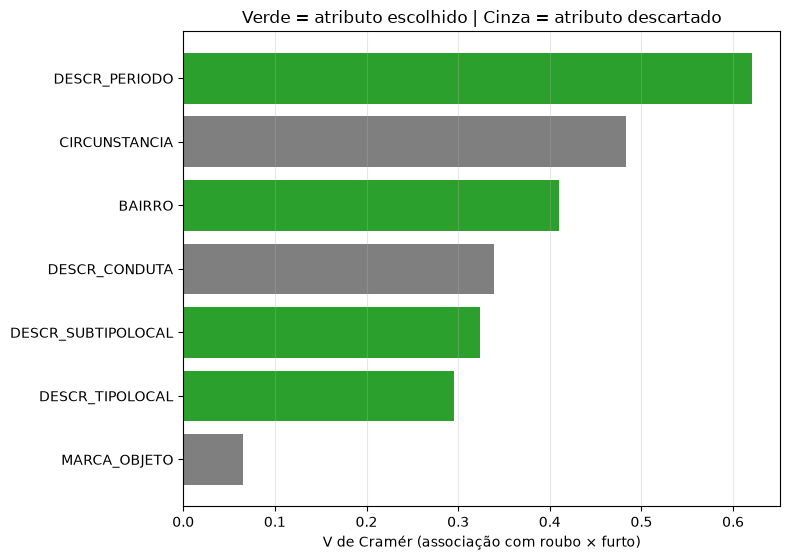

In [6]:
# Define a função que calcula o V de Cramér entre uma coluna categórica e o alvo binário.
def v_de_cramer(serie_categorica, serie_alvo):
    # Monta a tabela de contingência (categorias nas linhas, classes do alvo nas colunas).
    tabela = pd.crosstab(serie_categorica, serie_alvo)
    # Interrompe com NaN se a tabela não tiver pelo menos 2 linhas e 2 colunas.
    if tabela.shape[0] < 2 or tabela.shape[1] < 2:
        # Devolve NaN porque o teste não se aplica a tabelas degeneradas.
        return np.nan
    # Executa o teste de chi-quadrado e guarda apenas a estatística (primeiro retorno).
    chi2 = chi2_contingency(tabela)[0]
    # Obtém o total de observações válidas usadas na tabela.
    n = tabela.to_numpy().sum()
    # Calcula o menor grau de liberdade entre linhas e colunas, usado na normalização.
    menor_dimensao = min(tabela.shape) - 1
    # Devolve o V de Cramér: raiz de (chi2 / (n * menor dimensão)).
    return float(np.sqrt(chi2 / (n * menor_dimensao)))

# Inicializa a lista que vai receber a associação de cada atributo com o alvo.
linhas_assoc = []
# Percorre todos os atributos candidatos (escolhidos e descartados).
for coluna in candidatos:
    # Substitui ausências por um rótulo explícito, para não perder linhas no cruzamento.
    serie = df[coluna].fillna('(ausente)').astype(str)
    # Calcula o V de Cramér entre o atributo e o alvo.
    v = v_de_cramer(serie, df['target'])
    # Guarda o resultado do atributo.
    linhas_assoc.append({
        # Nome do atributo.
        'atributo': coluna,
        # Situação no projeto.
        'situacao': 'escolhido' if coluna in escolhidos else 'descartado',
        # Valor do V de Cramér arredondado.
        'V_de_Cramer': round(v, 4) if v == v else np.nan,
        # Cardinalidade, para avaliar o custo de incluir o atributo.
        'n_categorias': serie.nunique(),
    })

# Converte em DataFrame e ordena pela associação, do maior para o menor.
df_assoc = pd.DataFrame(linhas_assoc).sort_values('V_de_Cramer', ascending=False)
# Exibe o cabeçalho da tabela.
print('Associação de cada atributo com o alvo (V de Cramér, 0 a 1):')
# Imprime a tabela ordenada.
print(df_assoc.to_string(index=False))

# Cria a figura do gráfico de barras horizontais da associação.
fig, ax = plt.subplots(figsize=(8, 0.6 * len(df_assoc) + 1.5))
# Define a cor de cada barra conforme a situação do atributo no projeto.
cores = ['tab:green' if s == 'escolhido' else 'tab:gray' for s in df_assoc['situacao']]
# Desenha as barras horizontais com os valores do V de Cramér.
ax.barh(df_assoc['atributo'], df_assoc['V_de_Cramer'], color=cores)
# Inverte o eixo vertical para o maior valor aparecer no topo.
ax.invert_yaxis()
# Define o rótulo do eixo horizontal.
ax.set_xlabel('V de Cramér (associação com roubo × furto)')
# Define o título do gráfico.
ax.set_title('Verde = atributo escolhido | Cinza = atributo descartado')
# Adiciona grade vertical leve.
ax.grid(axis='x', alpha=0.3)
# Ajusta as margens.
fig.tight_layout()
# Exibe a figura.
plt.show()

## 7. Taxa de roubo por categoria (atributos escolhidos)

Se um atributo é útil, a taxa de roubo varia bastante entre suas categorias. Se todas as categorias ficam perto da média geral, o atributo separa pouco.

Taxa global de roubo: 42.1%


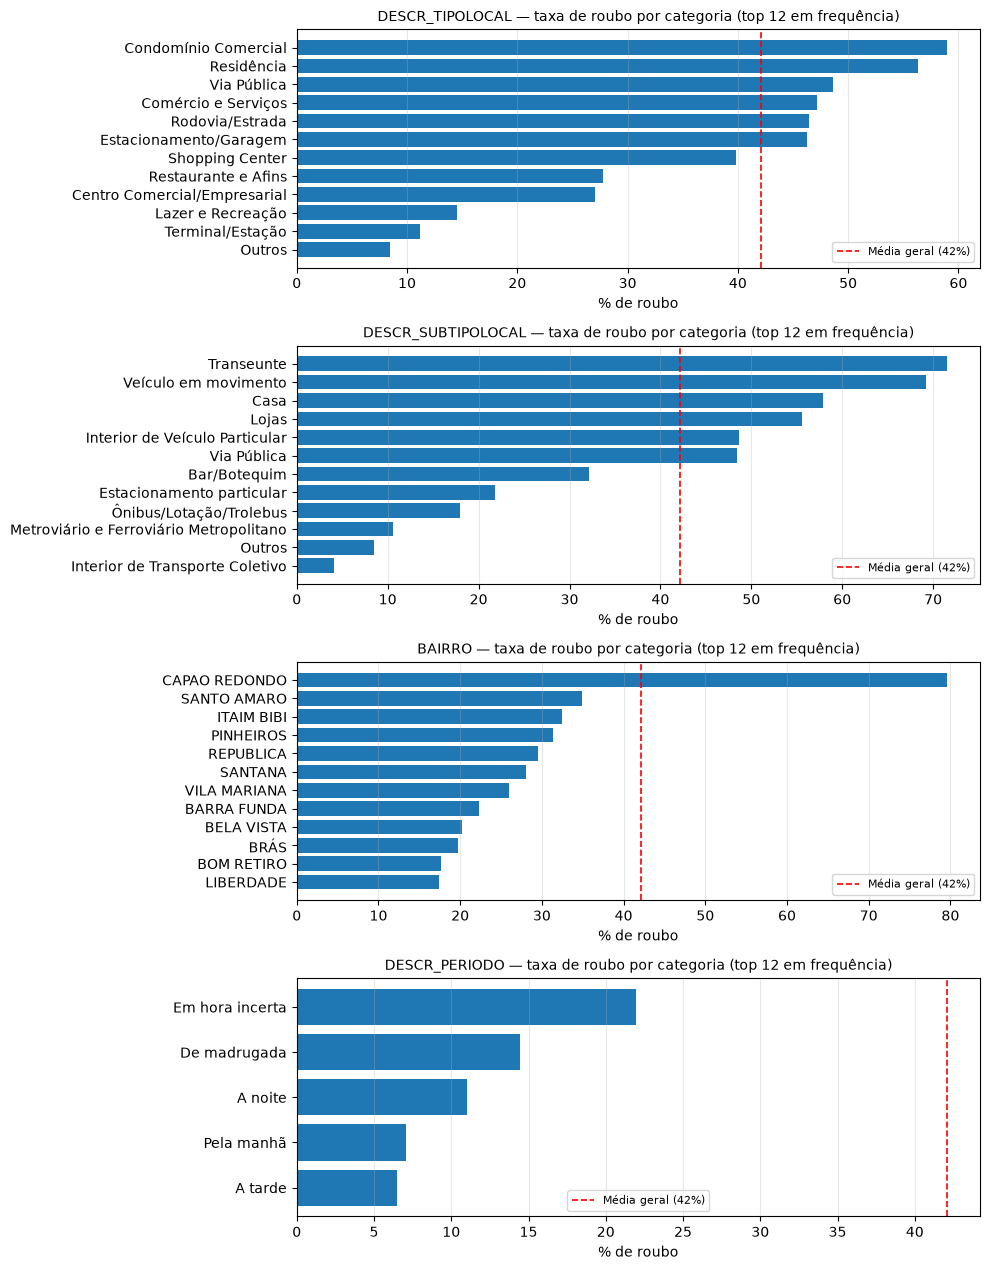

In [7]:
# Calcula a taxa média de roubo no recorte, usada como linha de referência nos gráficos.
taxa_global = df['target'].mean()
# Exibe a taxa global de roubo em percentual.
print(f'Taxa global de roubo: {100 * taxa_global:.1f}%')

# Define quantas categorias mais frequentes serão exibidas por atributo.
top_n = 12
# Cria uma grade de gráficos com uma linha por atributo escolhido.
fig, eixos = plt.subplots(len(escolhidos), 1, figsize=(10, 3.2 * len(escolhidos)))
# Percorre os atributos escolhidos junto com seu eixo correspondente.
for ax, coluna in zip(eixos, escolhidos):
    # Seleciona as categorias mais frequentes do atributo (as raras têm taxa instável).
    categorias_frequentes = df[coluna].value_counts().head(top_n).index
    # Filtra o DataFrame para manter apenas essas categorias.
    recorte = df[df[coluna].isin(categorias_frequentes)]
    # Calcula a taxa de roubo e o número de linhas por categoria.
    resumo = recorte.groupby(coluna)['target'].agg(['mean', 'size']).sort_values('mean')
    # Desenha as barras horizontais com a taxa de roubo de cada categoria.
    ax.barh(resumo.index.astype(str), 100 * resumo['mean'], color='tab:blue')
    # Desenha a linha vertical tracejada com a taxa global, como referência.
    ax.axvline(100 * taxa_global, color='red', ls='--', lw=1.2, label=f'Média geral ({100 * taxa_global:.0f}%)')
    # Define o título do painel com o nome do atributo.
    ax.set_title(f'{coluna} — taxa de roubo por categoria (top {top_n} em frequência)', fontsize=10)
    # Define o rótulo do eixo horizontal.
    ax.set_xlabel('% de roubo')
    # Mostra a legenda da linha de referência.
    ax.legend(fontsize=8)
    # Adiciona grade vertical leve.
    ax.grid(axis='x', alpha=0.3)
# Ajusta o espaçamento entre os painéis.
fig.tight_layout()
# Exibe a figura.
plt.show()

## 8. Atributos descartados: por que ficaram fora

Há dois motivos possíveis para descartar um atributo:

1. **Associação fraca** com o alvo — não ajuda a separar roubo de furto;
2. **Vazamento (data leakage)** — descreve a própria natureza da ocorrência. Nesse caso o atributo "acerta" porque repete a resposta, não porque descreve o contexto. O `AGENTS.md` proíbe usar a natureza da ocorrência e seus derivados como entrada.

In [8]:
# Verifica se há atributos descartados presentes no arquivo para analisar.
if not descartados:
    # Avisa que nenhuma das colunas descartadas existe nesta base.
    print('Nenhum dos atributos descartados existe neste arquivo.')
# Caso existam, analisa cada um deles.
else:
    # Percorre cada atributo descartado.
    for coluna in descartados:
        # Imprime o cabeçalho da análise do atributo.
        print(f'\n=== {coluna} ===')
        # Calcula a taxa de roubo e a contagem por categoria, para as 10 mais frequentes.
        resumo = (df.groupby(coluna)['target'].agg(['mean', 'size'])
                  # Ordena pela frequência para olhar primeiro as categorias relevantes.
                  .sort_values('size', ascending=False).head(10))
        # Converte a taxa de roubo para percentual, facilitando a leitura.
        resumo['% roubo'] = (100 * resumo['mean']).round(1)
        # Renomeia a coluna de contagem.
        resumo = resumo.rename(columns={'size': 'linhas'})[['linhas', '% roubo']]
        # Imprime a tabela do atributo.
        print(resumo.to_string())
        # Conta quantas categorias têm taxa de roubo em 0% ou 100% (indício de vazamento).
        taxas = df.groupby(coluna)['target'].mean()
        # Calcula quantas categorias são completamente determinísticas.
        n_deterministicas = int(((taxas == 0) | (taxas == 1)).sum())
        # Informa o total de categorias e quantas delas determinam a classe sozinhas.
        print(f'Categorias totais: {taxas.size} | com taxa 0% ou 100%: {n_deterministicas}')
        # Alerta quando a maioria das categorias determina a classe (forte indício de vazamento).
        if taxas.size and n_deterministicas / taxas.size > 0.5:
            # Imprime o alerta de vazamento para este atributo.
            print('  ⚠ Mais da metade das categorias determina a classe: indício de vazamento.')


=== DESCR_CONDUTA ===
                                 linhas  % roubo
DESCR_CONDUTA                                   
Outros                           139231     34.8
Transeunte                        22101     65.3
Veículo                            9114     94.5
Interior de Veículo                4171     46.0
Interior Transporte Coletivo       2024      5.1
Residência                         1916     59.2
Interior Estabelecimento           1625     40.9
Estabelecimento Comercial          1587     49.1
Carga                               968     99.8
Aplicativo de Mobilidade Urbana     353     47.9
Categorias totais: 19 | com taxa 0% ou 100%: 1

=== CIRCUNSTANCIA ===
                                                                                                                                                                                                                                                                                   linhas  % roubo
CIRCUNSTANCIA               

## 9. Derivados temporais (`hora`, `dia_semana`, `mes`)

Os três derivados entram como numéricos no modelo. Aqui se verifica se a taxa de roubo varia ao longo do dia, da semana e do ano.

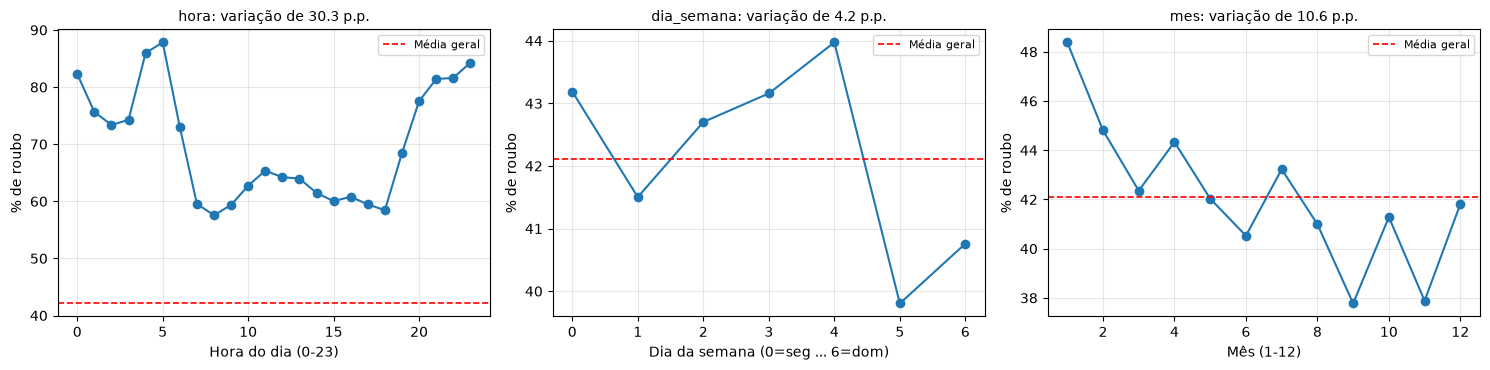

Amplitude da taxa de roubo em cada derivado (quanto maior, mais o atributo separa):
  hora         mín  57.6% | máx  87.8% | amplitude  30.3 p.p.
  dia_semana   mín  39.8% | máx  44.0% | amplitude   4.2 p.p.
  mes          mín  37.8% | máx  48.4% | amplitude  10.6 p.p.


: 

In [ ]:
# Cria uma cópia do recorte para acrescentar as colunas derivadas sem alterar o original.
df_tempo = df.copy()
# Converte a data da ocorrência para datetime, transformando valores inválidos em NaT.
df_tempo['DATA_OCORRENCIA_BO'] = pd.to_datetime(df_tempo['DATA_OCORRENCIA_BO'], errors='coerce')
# Extrai o dia da semana (0 = segunda ... 6 = domingo).
df_tempo['dia_semana'] = df_tempo['DATA_OCORRENCIA_BO'].dt.dayofweek
# Extrai o mês (1 a 12).
df_tempo['mes'] = df_tempo['DATA_OCORRENCIA_BO'].dt.month
# Extrai a hora inteira a partir do texto 'HH:MM:SS', devolvendo NaN quando não dá para converter.
df_tempo['hora'] = pd.to_numeric(df_tempo['HORA_OCORRENCIA'].astype(str).str.slice(0, 2), errors='coerce')

# Define os três derivados e os rótulos usados nos gráficos.
derivados = [('hora', 'Hora do dia (0-23)'), ('dia_semana', 'Dia da semana (0=seg ... 6=dom)'), ('mes', 'Mês (1-12)')]
# Cria uma grade com um painel por derivado.
fig, eixos = plt.subplots(1, 3, figsize=(15, 3.8))
# Percorre os derivados com seus eixos.
for ax, (coluna, rotulo) in zip(eixos, derivados):
    # Calcula a taxa de roubo e a contagem de linhas por valor do derivado.
    resumo = df_tempo.groupby(coluna)['target'].agg(['mean', 'size'])
    # Desenha a linha da taxa de roubo ao longo dos valores do derivado.
    ax.plot(resumo.index, 100 * resumo['mean'], marker='o', color='tab:blue')
    # Desenha a linha horizontal tracejada com a taxa global, como referência.
    ax.axhline(100 * taxa_global, color='red', ls='--', lw=1.2, label='Média geral')
    # Define o rótulo do eixo horizontal.
    ax.set_xlabel(rotulo)
    # Define o rótulo do eixo vertical.
    ax.set_ylabel('% de roubo')
    # Define o título do painel com a amplitude de variação do derivado.
    ax.set_title(f'{coluna}: variação de {100 * (resumo["mean"].max() - resumo["mean"].min()):.1f} p.p.', fontsize=10)
    # Mostra a legenda.
    ax.legend(fontsize=8)
    # Adiciona grade leve.
    ax.grid(alpha=0.3)
# Ajusta o espaçamento entre painéis.
fig.tight_layout()
# Exibe a figura.
plt.show()

# Imprime o cabeçalho do resumo numérico dos derivados.
print('Amplitude da taxa de roubo em cada derivado (quanto maior, mais o atributo separa):')
# Percorre os derivados para imprimir a amplitude de cada um.
for coluna, _ in derivados:
    # Calcula a taxa de roubo por valor do derivado.
    taxas = df_tempo.groupby(coluna)['target'].mean()
    # Imprime o mínimo, o máximo e a amplitude em pontos percentuais.
    print(f'  {coluna:12s} mín {100 * taxas.min():5.1f}% | máx {100 * taxas.max():5.1f}% | amplitude {100 * (taxas.max() - taxas.min()):5.1f} p.p.')

## 10. Conclusões

Preencher após executar as células, confrontando os números obtidos com a decisão registrada no `README.md`:

| Pergunta | Onde olhar | Conclusão |
|---|---|---|
| Os 4 atributos escolhidos têm associação maior que os descartados? | Seção 6 (V de Cramér) | *a preencher* |
| Algum descartado foi removido por vazamento, e não por associação fraca? | Seção 8 (taxas 0%/100%) | *a preencher* |
| `BAIRRO` justifica a alta cardinalidade que gera? | Seções 5 e 6 | *a preencher* |
| Os derivados temporais variam o suficiente para entrar? | Seção 9 (amplitude) | *a preencher* |
| Algum atributo disponível na fonte e não avaliado merece teste? | Seção 2 (lista de colunas) | *a preencher* |

> Se alguma conclusão contrariar a decisão de 2026-11-10, registrar no `README.md` como decisão **SUBSTITUÍDA**, preservando o histórico anterior.